# Deteksi Atribut Seragam Sekolah
**Metode:** HOG (Histogram of Oriented Gradients) + SVM (Support Vector Machine)  
**Atribut yang dideteksi:** Dasi, Logo Sekolah, Topi, Ikat Pinggang

---
## Struktur Notebook
1. Import Library
2. Konfigurasi Global
3. Fungsi Preprocessing & Feature Extraction
4. Fungsi Augmentasi Data
5. Fungsi Dataset Loader
6. Training Model
7. Hard Negative Mining
8. Evaluasi Model pada Test Set
9. Fungsi Deteksi
10. Real-time Webcam Detection


---
## 1. Import Library

In [1]:
import os
import cv2
import numpy as np
import random
import xml.etree.ElementTree as ET
import pickle
import time

from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, average_precision_score, f1_score
from sklearn.preprocessing import label_binarize

# Seed (angka awal) dipakai oleh fungsi random
# Tujuannya: supaya setiap kali notebook dijalankan ulang,
# hasil augmentasi dan pengambilan background patch selalu sama
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
cv2.setRNGSeed(SEED)
    
print('[+] Semua library berhasil diimport.')
print(f'    Random seed : {SEED}')


[+] Semua library berhasil diimport.
    Random seed : 42


---
## 2. Konfigurasi Global
Semua konstanta dan parameter dikumpulkan di sini agar mudah diubah.

In [2]:
# Label mapping 
# Setiap objek di dataset diberi nomor: 0=Dasi, 1=Logo, 2=Topi, 3=Ikat Pinggang
# Kamus ini mengubah angka tersebut jadi nama yang mudah dibaca
label_map = {
    '0' : 'Dasi',
    '1' : 'Logo Sekolah',
    '2' : 'Topi',
    '3' : 'Ikat Pinggang',
    '99': 'Background',
}

# Daftar atribut yang ditampilkan di checklist (Background tidak ditampilkan)
checklist_items = ['Logo Sekolah', 'Dasi', 'Ikat Pinggang', 'Topi']

# Path file model 
# Model yang sudah ditraining akan disimpan ke file ini
model_filename = 'svm_seragam_model.pkl'

# Ukuran input gambar 
# Setiap crop (potongan gambar) akan di-resize ke ukuran ini sebelum diekstrak HOG-nya
input_size = (96, 96)

# Parameter sliding window 
# Sliding window = kotak kecil yang digeser ke seluruh frame saat deteksi
sliding_window_w    = 96    # lebar kotak (piksel)
sliding_window_h    = 96    # tinggi kotak (piksel)
sliding_window_step = 64    # seberapa jauh kotak bergeser setiap langkah

# Skala resolusi yang dipakai saat deteksi
# Frame akan di-resize ke resolusi ini sebelum sliding window dijalankan
detection_scales = [
    (320, 240),   # satu skala — cukup untuk kecepatan ~10 FPS
]

# Parameter webcam 
full_w             = 640    # lebar frame webcam
full_h             = 480    # tinggi frame webcam
process_every_n_frames = 8  # deteksi dijalankan setiap 8 frame sekali (hemat CPU)

# Confidence threshold per kelas 
# Deteksi hanya diterima jika confidence-nya di atas angka ini
# Semakin tinggi angkanya → lebih sedikit false positive, tapi bisa lebih banyak miss
class_thresholds = {
    'Topi'         : 0.88,  # threshold tinggi karena kelas ini sering false positive
    'Dasi'         : 0.85,  # threshold sedang — hasil evaluasi sudah cukup seimbang
    'Logo Sekolah' : 0.75,  # threshold rendah karena kelas ini sering tidak terdeteksi
    'Ikat Pinggang': 0.72,  # threshold paling rendah karena paling sering terlewat
}

# Haar Cascade untuk mendeteksi wajah 
# Wajah yang terdeteksi akan dikecualikan dari area sliding window
# supaya kepala tidak salah diklasifikasi sebagai topi
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

print('[+] Konfigurasi global selesai.')
print(f'    Label classes : {list(label_map.values())}')
print(f'    Input size    : {input_size}')
print(f'    Scales        : {detection_scales}')


[+] Konfigurasi global selesai.
    Label classes : ['Dasi', 'Logo Sekolah', 'Topi', 'Ikat Pinggang', 'Background']
    Input size    : (96, 96)
    Scales        : [(320, 240)]


---
## 3. Fungsi Preprocessing & Feature Extraction
Sebelum gambar dimasukkan ke model SVM, gambar perlu diproses terlebih dahulu.
Ada dua tahap utama:
1. **CLAHE** — normalisasi pencahayaan supaya model tidak terpengaruh oleh kondisi cahaya
2. **HOG** — mengekstrak pola tepi dan tekstur dari gambar menjadi vektor fitur angka


In [3]:
def apply_clahe(image):
    """
    Normalisasi pencahayaan menggunakan CLAHE (Contrast Limited Adaptive Histogram Equalization).

    Cara kerja:
      - Gambar diubah ke colorspace LAB (L = kecerahan, A & B = warna)
      - CLAHE diterapkan hanya pada channel L (kecerahan)
      - Gambar dikembalikan ke colorspace BGR

    Hasilnya: gambar tetap terlihat natural, tapi pencahayaannya lebih merata
    sehingga model lebih tahan terhadap foto yang redup, terlalu terang, atau backlight.
    """
    lab   = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)


def extract_hog_features(image):
    """
    Ubah gambar menjadi vektor fitur HOG yang bisa dipahami oleh SVM.

    Pipeline (urutan proses):
      1. Resize gambar ke 96x96 piksel (ukuran standar)
      2. CLAHE — normalisasi pencahayaan
      3. HOG — ekstraksi fitur tepi dan tekstur

    Parameter HOG:
      - orientations=9  : 9 arah gradien yang diperhitungkan
      - pixels_per_cell : setiap cell berukuran 8x8 piksel
      - cells_per_block : setiap block terdiri dari 2x2 cell
      - block_norm='L2-Hys' : normalisasi antar-block
      - channel_axis=-1 : HOG dijalankan per channel warna (RGB)
    """
    resized = cv2.resize(image, input_size)
    resized = apply_clahe(resized)   # normalisasi pencahayaan
    features = hog(
        resized,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        transform_sqrt=True,
        channel_axis=-1
    )
    return features


def is_overlap(box1, box2):
    """
    Cek apakah dua bounding box saling tumpang tindih.

    Setiap box dinyatakan sebagai (xmin, ymin, xmax, ymax).
    Fungsi ini hanya membandingkan koordinat — tidak ada operasi gambar.
    """
    if box1[0] >= box2[2] or box2[0] >= box1[2]: return False
    if box1[1] >= box2[3] or box2[1] >= box1[3]: return False
    return True


print('[+] Fungsi preprocessing & feature extraction siap.')


[+] Fungsi preprocessing & feature extraction siap.


---
## 4. Fungsi Augmentasi Data
Augmentasi adalah teknik memperbanyak data training dengan membuat variasi dari gambar yang ada.
Tujuannya agar model lebih tahan terhadap kondisi nyata (foto miring, buram, gelap, dsb.).

Setiap gambar objek akan diaugmentasi sebanyak **5 kali** dengan kombinasi acak dari 6 jenis augmentasi berikut:

| # | Jenis | Tujuan |
|---|-------|--------|
| 1 | Rotasi ±15° | Meniru objek yang miring atau condong |
| 2 | Gaussian Blur | Meniru foto yang buram atau goyang |
| 3 | Gaussian Noise | Meniru noise dari kamera berkualitas rendah |
| 4 | Flip Horizontal | Meniru objek di sisi kiri maupun kanan |
| 5 | Random Brightness | Meniru variasi pencahayaan ruangan |
| 6 | Random Zoom | Meniru objek yang dekat atau jauh dari kamera |


In [4]:
def augment_patch(patch):
    """
    Terapkan augmentasi acak pada satu patch gambar.
    Dipanggil 5 kali per gambar objek saat proses training.
    Setiap panggilan menghasilkan kombinasi augmentasi yang berbeda.
    """
    aug = patch.copy()
    h, w = aug.shape[:2]

    # 1. Rotasi acak antara -15 hingga +15 derajat
    angle = random.uniform(-15, 15)
    M     = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    aug   = cv2.warpAffine(aug, M, (w, h), borderMode=cv2.BORDER_REPLICATE)

    # 2. Gaussian Blur — membuat gambar sedikit buram (probabilitas 50%)
    if random.random() > 0.5:
        k   = random.choice([3, 5])    # ukuran kernel blur (3x3 atau 5x5)
        aug = cv2.GaussianBlur(aug, (k, k), 0)

    # 3. Gaussian Noise — menambah sedikit butiran noise (probabilitas 50%)
    if random.random() > 0.5:
        noise = np.zeros((h, w, 3), np.uint8)
        cv2.randn(noise, 0, 15)    # noise dengan standar deviasi 15
        aug = cv2.add(aug, noise)

    # 4. Flip Horizontal — cerminkan gambar secara horizontal (probabilitas 50%)
    if random.random() > 0.5:
        aug = cv2.flip(aug, 1)

    # 5. Random Brightness — ubah kecerahan secara acak (probabilitas 50%)
    if random.random() > 0.5:
        delta = random.randint(-40, 40)    # terangkan atau gelapkan
        aug   = np.clip(aug.astype(np.int16) + delta, 0, 255).astype(np.uint8)

    # 6. Random Zoom — perbesar atau perkecil gambar antara 80%-120% (probabilitas 50%)
    if random.random() > 0.5:
        scale  = random.uniform(0.80, 1.20)
        new_w  = max(1, int(w * scale))
        new_h  = max(1, int(h * scale))
        zoomed = cv2.resize(aug, (new_w, new_h))
        # Kembalikan ke ukuran semula: crop tengah jika zoom in, resize jika zoom out
        if scale >= 1.0:            # zoom in → potong bagian tengah
            x0  = (new_w - w) // 2
            y0  = (new_h - h) // 2
            aug = zoomed[y0:y0 + h, x0:x0 + w]
        else:                       # zoom out → resize balik ke ukuran semula
            aug = cv2.resize(zoomed, (w, h))

    return aug


print('[+] Fungsi augmentasi siap (6 jenis, 5x per crop).')


[+] Fungsi augmentasi siap (6 jenis, 5x per crop).


---
## 5. Fungsi Dataset Loader
Fungsi ini membaca dataset dari folder yang berisi pasangan file gambar (`.jpg`) dan anotasi (`.xml`).

Format anotasi yang digunakan adalah **Pascal VOC XML** — setiap file XML menyimpan koordinat
bounding box dari setiap objek dalam gambar.

Selain memuat objek positif, fungsi ini juga mengambil patch **background**
menggunakan metode **grid sistematis**: gambar dibagi menjadi kotak-kotak kecil,
lalu kotak yang tidak mengenai objek manapun diambil sebagai contoh background.


In [5]:
def sample_background_grid(image, obj_boxes, n_target):
    """
    Ambil background patch menggunakan grid sistematis.

    Cara kerja:
      - Bagi gambar jadi grid dengan step = input_size (96px)
      - Tiap cell dicek: kalau tidak overlap dengan objek manapun → ambil sebagai BG
      - Kalau hasil grid > n_target → shuffle & ambil n_target saja

    Args:
        image     : gambar asli (BGR)
        obj_boxes : list koordinat [xmin,ymin,xmax,ymax] semua objek di gambar
        n_target  : jumlah maksimal patch yang diambil

    Returns:
        list fitur HOG dari patch background yang lolos
    """
    img_h, img_w = image.shape[:2]
    step_x, step_y = input_size[0], input_size[1]
    candidates = []

    for gy in range(0, img_h - step_y + 1, step_y):
        for gx in range(0, img_w - step_x + 1, step_x):
            cell = [gx, gy, gx + step_x, gy + step_y]
            # Abaikan kotak yang mengenai area objek (tidak boleh dijadikan background)
            overlap = any(is_overlap(cell, ob) for ob in obj_boxes)
            if not overlap:
                candidates.append(cell)

    # Urutkan dulu agar urutan selalu konsisten, lalu acak dengan seed yang sudah di-fix
    # Ini penting supaya hasil sampling sama setiap kali notebook dijalankan
    candidates.sort()
    random.shuffle(candidates)

    features = []
    for cell in candidates[:n_target]:
        crop = image[cell[1]:cell[3], cell[0]:cell[2]]
        if crop.shape[0] == step_y and crop.shape[1] == step_x:
            features.append(extract_hog_features(crop))

    return features


def load_data_from_voc(directory, is_training=True):
    """
    Muat dataset dari folder yang berisi file .jpg dan .xml (format Pascal VOC).

    Parameter:
      directory   : path ke folder dataset (misal: 'train' atau 'test')
      is_training : True saat memuat data training (augmentasi diaktifkan)

    Return:
      X : array fitur HOG dari setiap sampel
      y : array label kelas dari setiap sampel
    """
    X, y = [], []

    if not os.path.exists(directory):
        print(f'[-] Folder "{directory}" tidak ditemukan.')
        return np.array([]), np.array([])

    xml_files = [f for f in os.listdir(directory) if f.endswith('.xml')]
    print(f'[*] Memuat {len(xml_files)} file dari "{directory}"...')

    for xml_file in xml_files:
        xml_path = os.path.join(directory, xml_file)
        tree     = ET.parse(xml_path)
        root     = tree.getroot()

        img_filename = root.find('filename').text
        img_path     = os.path.join(directory, img_filename)
        if not os.path.exists(img_path):
            img_path = xml_path.replace('.xml', '.jpg')

        image = cv2.imread(img_path)
        if image is None:
            continue

        img_h, img_w = image.shape[:2]
        obj_boxes    = []

        # Baca semua objek (bounding box + label) dari file XML
        for obj in root.findall('object'):
            label = obj.find('name').text.strip()

            # Normalisasi label ke string numerik
            label_lower = label.lower()
            if label in ['0', '1', '2', '3']:
                norm_label = label                     # sudah benar
            elif label_lower in ['dasi', 'tie']:       norm_label = '0'
            elif label_lower in ['logo', 'logo sekolah', 'badge']: norm_label = '1'
            elif label_lower in ['topi', 'hat']:       norm_label = '2'
            elif label_lower in ['sabuk', 'ikat pinggang', 'belt']: norm_label = '3'
            else:
                continue   # label tidak dikenal, skip

            xmlbox = obj.find('bndbox')
            xmin   = max(0,     int(float(xmlbox.find('xmin').text)))
            ymin   = max(0,     int(float(xmlbox.find('ymin').text)))
            xmax   = min(img_w, int(float(xmlbox.find('xmax').text)))
            ymax   = min(img_h, int(float(xmlbox.find('ymax').text)))

            if xmax <= xmin or ymax <= ymin:
                continue   # bounding box tidak valid

            obj_boxes.append([xmin, ymin, xmax, ymax])
            crop = image[ymin:ymax, xmin:xmax]
            if crop.size == 0:
                continue

            X.append(extract_hog_features(crop))
            y.append(norm_label)

            # Augmentasi: buat 5 variasi gambar per objek saat training
            if is_training:
                for _ in range(5):
                    X.append(extract_hog_features(augment_patch(crop)))
                    y.append(norm_label)

        # Ambil patch background dari area yang tidak mengandung objek
        # Jumlah background proporsional: min 6, maks 20, default = jumlah objek × 2
        n_bg      = max(6, min(len(obj_boxes) * 2, 20)) if is_training else max(2, len(obj_boxes))
        bg_feats  = sample_background_grid(image, obj_boxes, n_bg)
        for feat in bg_feats:
            X.append(feat)
            y.append('99')

    print(f'[+] Dataset "{directory}" selesai dimuat: {len(X)} sampel total.')

    # Tampilkan distribusi jumlah sampel per kelas
    from collections import Counter
    dist = Counter(y)
    print(f'\n    Distribusi kelas di "{directory}":')
    for lbl in sorted(dist.keys()):
        nama  = label_map.get(str(lbl), f'Class {lbl}')
        count = dist[lbl]
        bar   = '█' * (count // 50)
        print(f'    {nama:<15} ({lbl}): {count:>5} sampel  {bar}')
    print()

    return np.array(X), np.array(y)


print('[+] Fungsi dataset loader siap.')

[+] Fungsi dataset loader siap.


---
## 6. Training Model
Model yang dipakai adalah **SVM (Support Vector Machine)** dengan kernel linear.
SVM cocok untuk klasifikasi berbasis fitur HOG karena bekerja baik
pada data berdimensi tinggi.

Sebelum training, nilai parameter `C` dipilih secara otomatis menggunakan
folder `valid/` — proses ini disebut **hyperparameter tuning**.
Metric yang digunakan adalah **macro F1-score** (bukan accuracy) karena
jumlah sampel tiap kelas tidak seimbang.

| Komponen | Detail |
|----------|--------|
| Algoritma | SVM kernel linear |
| Kandidat C | 0.1, 1.0 |
| Metric tuning | Macro F1-score |
| Data tuning | Folder `valid/` |
| Evaluasi final | Folder `test/` (hanya sekali) |

```
train/  → dipakai untuk melatih model
valid/  → dipakai untuk memilih parameter terbaik
test/   → dipakai untuk evaluasi akhir (satu kali saja)
```


In [6]:
# Daftar nilai C yang akan dicoba saat hyperparameter tuning
# C mengontrol seberapa ketat SVM menghindari kesalahan klasifikasi:
# C kecil = lebih toleran terhadap kesalahan (model lebih general)
# C besar = lebih ketat (model bisa overfit)
C_CANDIDATES = [0.1, 1.0]

if os.path.exists(model_filename):
    # Jika file model sudah ada, langsung dimuat — training dilewati
    print(f'[*] Memuat model tersimpan dari "{model_filename}"...')
    with open(model_filename, 'rb') as f:
        svm_model = pickle.load(f)
    print('[+] Model berhasil dimuat. Skip training & tuning.')

else:
    # Muat data training dari folder 'train'
    print('[*] Memuat data training...')
    X_train, y_train = load_data_from_voc('train', is_training=True)

    # Hyperparameter tuning: coba setiap nilai C, pilih yang terbaik
    valid_dir = 'valid'
    if os.path.exists(valid_dir):
        print('\n[*] Memuat data validasi untuk hyperparameter tuning...')
        X_valid, y_valid = load_data_from_voc(valid_dir, is_training=False)

        best_C     = C_CANDIDATES[0]
        best_score = 0.0

        print('\n' + '='*55)
        print('       HYPERPARAMETER TUNING (via valid/)')
        print('='*55)

        for C_val in C_CANDIDATES:
            tmp_model = SVC(kernel='linear', C=C_val, probability=True, random_state=42)
            tmp_model.fit(X_train, y_train)
            # Macro F1: rata-rata F1 per kelas, semua kelas dianggap sama penting
            # Lebih adil dari accuracy karena Background jauh lebih banyak dari kelas objek
            score = f1_score(y_valid, tmp_model.predict(X_valid), average='macro', zero_division=0)
            marker = '  <-- BEST' if score > best_score else ''
            print(f'  C={C_val:<6} | valid macro F1: {score*100:.2f}%{marker}')
            if score > best_score:
                best_score = score
                best_C     = C_val

        print(f'\n[+] C terbaik: {best_C}  (valid macro F1: {best_score*100:.2f}%)')
        print('='*55)
    else:
        print(f'[!] Folder "{valid_dir}" tidak ditemukan. Pakai C=1.0 (default).')
        best_C = 1.0

    # Training model final menggunakan nilai C terbaik
    print(f'\n[*] Training model final dengan C={best_C}...')
    svm_model = SVC(kernel='linear', C=best_C, probability=True, random_state=42)
    svm_model.fit(X_train, y_train)

    with open(model_filename, 'wb') as f:
        pickle.dump(svm_model, f)
    print(f'[+] Training selesai! Model disimpan ke "{model_filename}".')

[*] Memuat model tersimpan dari "svm_seragam_model.pkl"...
[+] Model berhasil dimuat. Skip training & tuning.


---
## 7. Hard Negative Mining
Hard Negative Mining adalah teknik untuk mengurangi **false positive** — yaitu saat model
salah mendeteksi area yang bukan objek sebagai objek.

**Cara kerja (2-pass training):**
```
Pass 1 → model awal dilatih dengan data biasa (cell 6)
Mining → model dijalankan ke semua gambar training menggunakan sliding window
         area yang salah diklasifikasi sebagai objek dikumpulkan (= hard negatives)
Pass 2 → hard negatives ditambahkan ke data training → model dilatih ulang
```

**Kenapa efektif?**  
Background biasa (tembok, lantai) mudah dibedakan oleh model.  
Hard negatives adalah area yang benar-benar mirip objek — melatih model dengan ini
membuatnya lebih pintar dalam membedakan objek asli dari area yang mirip.


In [7]:
def mine_hard_negatives(model, train_dir, max_per_image=20, conf_threshold=0.5):
    """
    Cari hard negatives dari gambar training menggunakan sliding window.

    Hard negatives = area di gambar yang bukan objek,
    tapi model awal salah menganggapnya sebagai objek (false positive).

    Parameter:
      model          : model SVM hasil training pass 1
      train_dir      : folder berisi gambar training
      max_per_image  : batas maksimal hard negative yang diambil per gambar
      conf_threshold : batas confidence minimum agar dianggap false positive

    Return:
      X_hard : fitur HOG dari semua hard negative yang ditemukan
      y_hard : label '99' (Background) untuk setiap hard negative
    """
    X_hard, y_hard = [], []

    if not os.path.exists(train_dir):
        print(f'[-] Folder "{train_dir}" tidak ditemukan.')
        return np.array([]), np.array([])

    xml_files = [f for f in os.listdir(train_dir) if f.endswith('.xml')]
    print(f'[*] Mining hard negatives dari {len(xml_files)} gambar training...')

    for xml_file in xml_files:
        xml_path = os.path.join(train_dir, xml_file)
        tree     = ET.parse(xml_path)
        root     = tree.getroot()

        img_filename = root.find('filename').text
        img_path     = os.path.join(train_dir, img_filename)
        if not os.path.exists(img_path):
            img_path = xml_path.replace('.xml', '.jpg')

        image = cv2.imread(img_path)
        if image is None:
            continue

        img_h, img_w = image.shape[:2]

        # Baca koordinat semua objek dari file XML
        # (untuk memastikan sliding window tidak mengenai area objek)
        obj_boxes = []
        for obj in root.findall('object'):
            label = obj.find('name').text.strip()
            if label not in ['0', '1', '2', '3']:
                continue
            xmlbox = obj.find('bndbox')
            xmin   = max(0,     int(float(xmlbox.find('xmin').text)))
            ymin   = max(0,     int(float(xmlbox.find('ymin').text)))
            xmax   = min(img_w, int(float(xmlbox.find('xmax').text)))
            ymax   = min(img_h, int(float(xmlbox.find('ymax').text)))
            if xmax > xmin and ymax > ymin:
                obj_boxes.append([xmin, ymin, xmax, ymax])

        # Geser sliding window di seluruh gambar untuk mencari area yang mengecoh model
        # Stride dilipatduakan agar proses lebih cepat
        hard_negs_this_image = []
        step = sliding_window_step * 2

        for gy in range(0, img_h - input_size[1], step):
            for gx in range(0, img_w - input_size[0], step):
                window_box = [gx, gy, gx + input_size[0], gy + input_size[1]]

                # Skip kalau window overlap dengan objek ground truth
                if any(is_overlap(window_box, ob) for ob in obj_boxes):
                    continue

                crop = image[gy:gy + input_size[1], gx:gx + input_size[0]]
                if crop.shape[:2] != (input_size[1], input_size[0]):
                    continue

                try:
                    feat   = extract_hog_features(crop)
                    proba  = model.predict_proba(feat.reshape(1, -1))[0]
                    pred   = model.predict(feat.reshape(1, -1))[0]
                    score  = proba.max()

                    # Jika model salah mendeteksi ini sebagai objek → simpan sebagai hard negative
                    if str(pred) in ['0', '1', '2', '3'] and score >= conf_threshold:
                        hard_negs_this_image.append(feat)
                        if len(hard_negs_this_image) >= max_per_image:
                            break   # sudah cukup untuk gambar ini, lanjut ke gambar berikutnya
                except Exception:
                    pass

            if len(hard_negs_this_image) >= max_per_image:
                break

        for feat in hard_negs_this_image:
            X_hard.append(feat)
            y_hard.append('99')

    print(f'[+] Total hard negatives ditemukan: {len(X_hard)} patch')
    return np.array(X_hard), np.array(y_hard)


# Jalankan Hard Negative Mining hanya jika model baru saja ditraining
# (bukan di-load dari file). Tandanya: variabel X_train masih ada di memori.

if 'X_train' in dir() and len(X_train) > 0:
    print('\n' + '='*55)
    print('         HARD NEGATIVE MINING (Pass 2)')
    print('='*55)

    X_hard, y_hard = mine_hard_negatives(
        model          = svm_model,
        train_dir      = 'train',
        max_per_image  = 15,       # max 15 hard neg per gambar
        conf_threshold = 0.5       # tangkap FP dengan confidence >= 50%
    )

    if len(X_hard) > 0:
        # Gabungkan data training original dengan hard negatives
        X_train_v2 = np.vstack([X_train, X_hard])
        y_train_v2 = np.concatenate([y_train, y_hard])

        print(f'[*] Dataset training v2: {len(X_train_v2)} sampel')
        print(f'    (original: {len(X_train)} + hard negatives: {len(X_hard)})')
        print(f'\n[*] Retrain model dengan hard negatives (Pass 2)...')

        svm_model = SVC(kernel='linear', C=best_C, probability=True, random_state=42)
        svm_model.fit(X_train_v2, y_train_v2)

        # Simpan model hasil pass 2 ke file
        with open(model_filename, 'wb') as f:
            pickle.dump(svm_model, f)
        print('[+] Pass 2 selesai! Model diperbarui dengan hard negatives.')
    else:
        print('[!] Tidak ada hard negative ditemukan. Model Pass 1 dipertahankan.')
else:
    print('[*] Model di-load dari file — Hard Negative Mining dilewati.')
    print('    Hapus svm_seragam_model.pkl dan jalankan ulang untuk mining.')

[*] Model di-load dari file — Hard Negative Mining dilewati.
    Hapus svm_seragam_model.pkl dan jalankan ulang untuk mining.


---
## 8. Evaluasi Model pada Test Set
Model dievaluasi menggunakan folder `test/` yang **tidak pernah dipakai saat training maupun tuning**.
Ini memastikan hasil evaluasi mencerminkan performa model pada data yang benar-benar baru.

Metrik yang ditampilkan:
- **Precision** — dari semua prediksi kelas X, berapa % yang benar?
- **Recall** — dari semua objek kelas X yang ada, berapa % yang berhasil dideteksi?
- **F1-score** — rata-rata harmonis dari precision dan recall
- **mAP** — Mean Average Precision, metrik standar object detection


[*] Memuat data test untuk evaluasi final...
[*] Memuat 24 file dari "test"...
[+] Dataset "test" selesai dimuat: 208 sampel total.

    Distribusi kelas di "test":
    Dasi            (0):    24 sampel  
    Logo Sekolah    (1):    22 sampel  
    Topi            (2):    42 sampel  
    Ikat Pinggang   (3):    12 sampel  
    Background      (99):   108 sampel  ██


              METRIC EVALUATION REPORT
               precision    recall  f1-score   support

         Dasi       0.72      0.75      0.73        24
 Logo Sekolah       0.83      0.86      0.84        22
         Topi       0.70      0.95      0.81        42
Ikat Pinggang       0.35      0.50      0.41        12
   Background       0.92      0.73      0.81       108

     accuracy                           0.78       208
    macro avg       0.70      0.76      0.72       208
 weighted avg       0.81      0.78      0.78       208

Accuracy Keseluruhan : 77.88%

Average Precision (AP) per kelas:
  - Dasi            : 82.63%

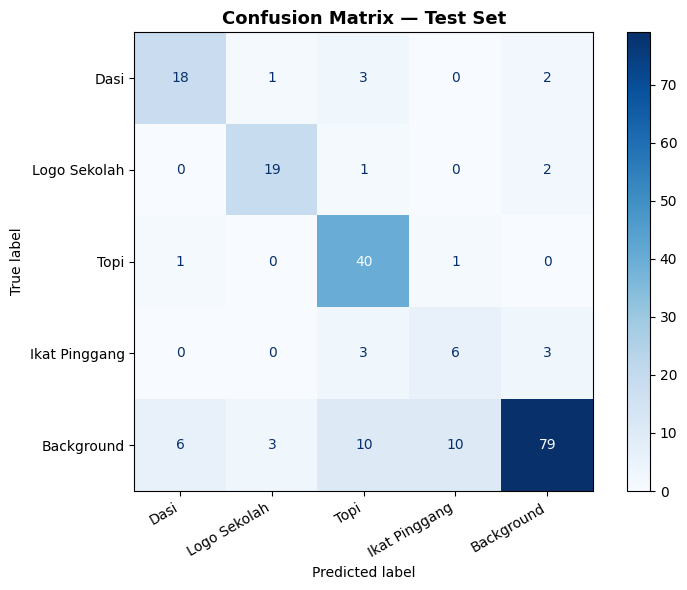

[+] Confusion matrix disimpan ke "confusion_matrix.png"
[+] Hasil evaluasi disimpan ke "evaluation_results.json"
{
    "timestamp": "2026-10-19 14:33:13",
    "model_file": "svm_seragam_model.pkl",
    "accuracy": 77.88,
    "mAP": 83.71,
    "per_kelas": {
        "Dasi": 82.63,
        "Logo Sekolah": 90.09,
        "Topi": 93.0,
        "Ikat Pinggang": 58.31,
        "Background": 94.5
    }
}


In [8]:
print('[*] Memuat data test untuk evaluasi final...')
X_test, y_test = load_data_from_voc('test', is_training=False)

if len(X_test) == 0:
    print('[-] Tidak ada data test yang bisa dimuat.')
else:
    y_pred = svm_model.predict(X_test)
    y_prob = svm_model.predict_proba(X_test)

    print('\n' + '='*60)
    print('              METRIC EVALUATION REPORT')
    print('='*60)

    unique_labels = sorted(list(set(y_test)))
    target_names  = [label_map.get(str(lbl), f'Class {lbl}') for lbl in unique_labels]

    print(classification_report(y_test, y_pred, target_names=target_names, digits=2))
    print(f'Accuracy Keseluruhan : {accuracy_score(y_test, y_pred) * 100:.2f}%\n')

    # Hitung Average Precision (AP) per kelas, lalu rata-ratakan menjadi mAP
    y_test_bin = label_binarize(y_test, classes=svm_model.classes_)
    ap_scores  = []

    print('Average Precision (AP) per kelas:')
    for i, cls in enumerate(svm_model.classes_):
        if np.sum(y_test_bin[:, i]) > 0:
            ap = average_precision_score(y_test_bin[:, i], y_prob[:, i])
            ap_scores.append(ap)
            nama = label_map.get(str(cls), str(cls))
            print(f'  - {nama:<15} : {ap*100:.2f}%')

    mAP = np.mean(ap_scores)
    print(f'\n=> mAP (Mean Average Precision) : {mAP*100:.2f}%')
    print('='*60)

    # Tampilkan Confusion Matrix — tabel yang menunjukkan prediksi vs label asli
    import matplotlib.pyplot as plt
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

    print('\n[*] Menampilkan Confusion Matrix...')
    cm      = confusion_matrix(y_test, y_pred, labels=svm_model.classes_)
    cm_disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[label_map.get(str(c), str(c)) for c in svm_model.classes_]
    )
    fig, ax = plt.subplots(figsize=(8, 6))
    cm_disp.plot(ax=ax, cmap='Blues', colorbar=True)
    ax.set_title('Confusion Matrix — Test Set', fontsize=13, fontweight='bold')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=150)
    plt.show()
    print('[+] Confusion matrix disimpan ke "confusion_matrix.png"')

    # ── Simpan Hasil Evaluasi ke File ─────────────────────────────────────────
    import json, datetime

    hasil_evaluasi = {
        'timestamp'  : datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'model_file' : model_filename,
        'accuracy'   : round(accuracy_score(y_test, y_pred) * 100, 2),
        'mAP'        : round(float(mAP) * 100, 2),
        'per_kelas'  : {}
    }

    for i, cls in enumerate(svm_model.classes_):
        if np.sum(y_test_bin[:, i]) > 0:
            ap   = average_precision_score(y_test_bin[:, i], y_prob[:, i])
            nama = label_map.get(str(cls), str(cls))
            hasil_evaluasi['per_kelas'][nama] = round(float(ap) * 100, 2)

    with open('evaluation_results.json', 'w') as f:
        json.dump(hasil_evaluasi, f, indent=4, ensure_ascii=False)

    print('[+] Hasil evaluasi disimpan ke "evaluation_results.json"')
    print(json.dumps(hasil_evaluasi, indent=4, ensure_ascii=False))

---
## 9. Fungsi Deteksi

In [9]:
def sliding_window(image, window_size, step_size):
    """
    Generator yang menghasilkan (x, y, roi) untuk setiap posisi window.
    x, y = koordinat pojok kiri atas window
    roi  = potongan gambar di posisi tersebut (Region of Interest)
    """
    win_w, win_h = window_size
    for y in range(0, image.shape[0] - win_h, step_size):
        for x in range(0, image.shape[1] - win_w, step_size):
            yield (x, y, image[y:y + win_h, x:x + win_w])


def apply_nms(boxes, confidences, overlap_threshold=0.3):
    """
    Non-Maximum Suppression menggunakan cv2.dnn.NMSBoxes.

    overlap_threshold=0.3 artinya kotak dengan tumpang tindih >30% akan dihapus.
    """
    if len(boxes) == 0:
        return []

    boxes_xywh  = [[b[0], b[1], b[2] - b[0], b[3] - b[1]] for b in boxes]
    conf_floats = [float(c) for c in confidences]

    indices = cv2.dnn.NMSBoxes(boxes_xywh, conf_floats, 0.1, overlap_threshold)
    if len(indices) == 0:
        return []

    results = []
    for i in indices:
        idx = i[0] if isinstance(i, (list, tuple, np.ndarray)) else i
        results.append(boxes[idx])
    return results


def detect_on_frame(frame, svm_model, face_cascade):
    """
    Jalankan deteksi pada satu frame.

    Cara kerja:

    Returns:
        final_detections : list dict {'box': (x1,y1,x2,y2), 'label': str, 'score': float}
        checklist_status : dict {label: bool}
        face_boxes       : array wajah terdeteksi (untuk display)
    """
    full_h, full_w = frame.shape[:2]

    # Deteksi wajah terlebih dahulu agar area wajah tidak ikut di-scan sliding window
    gray       = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    face_boxes = face_cascade.detectMultiScale(
        gray, scaleFactor=1.2, minNeighbors=5, minSize=(60, 60)
    )

    all_detections = {item: [] for item in checklist_items}
    all_scores     = {item: [] for item in checklist_items}

    # ── Multi-scale loop ──────────────────────────────────────────────────────
    for (det_w, det_h) in detection_scales:
        detect_frame = cv2.resize(frame, (det_w, det_h))
        scale_x      = full_w / det_w
        scale_y      = full_h / det_h

        # Scale koordinat wajah ke ruang deteksi
        scaled_faces = []
        for (fx, fy, fw, fh) in face_boxes:
            scaled_faces.append([
                int(fx / scale_x), int(fy / scale_y),
                int((fx + fw) / scale_x), int((fy + fh) / scale_y)
            ])

        for (x, y, roi) in sliding_window(
            detect_frame,
            (sliding_window_w, sliding_window_h),
            sliding_window_step
        ):
            if roi.shape[1] != sliding_window_w or roi.shape[0] != sliding_window_h:
                continue

            window_box = [x, y, x + sliding_window_w, y + sliding_window_h]

            # Cek apakah window overlap dengan wajah
            overlaps_face = any(is_overlap(window_box, fb) for fb in scaled_faces)

            try:
                feat       = extract_hog_features(roi)
                feat_2d    = feat.reshape(1, -1)
                proba      = svm_model.predict_proba(feat_2d)[0]
                prob_score = proba.max()
                pred_idx   = svm_model.classes_[proba.argmax()]  # ambil dari proba, tidak perlu predict() lagi
                label_indo = label_map.get(str(pred_idx), None)

                if label_indo not in checklist_items:
                    continue

                # Skip window yang overlap wajah, KECUALI untuk Topi
                # (Topi ada di kepala, justru harus di area wajah/kepala)
                if overlaps_face and label_indo != 'Topi':
                    continue

                # Zona vertikal (filter deteksi di posisi tidak masuk akal)
                center_y    = y + (sliding_window_h // 2)
                batas_atas  = det_h * 0.35
                batas_bawah = det_h * 0.65

                if label_indo == 'Topi' and center_y > batas_atas:
                    continue
                if label_indo in ['Dasi', 'Logo Sekolah'] and \
                   (center_y < det_h * 0.25 or center_y > det_h * 0.75):
                    continue
                if label_indo == 'Ikat Pinggang' and center_y < batas_bawah:
                    continue

                if prob_score > class_thresholds.get(label_indo, 0.85):
                    # Scale box kembali ke resolusi penuh
                    full_box = [
                        int(x  * scale_x), int(y  * scale_y),
                        int((x + sliding_window_w) * scale_x),
                        int((y + sliding_window_h) * scale_y)
                    ]
                    all_detections[label_indo].append(full_box)
                    all_scores[label_indo].append(prob_score)

            except Exception:
                pass

    # ── NMS per kelas, gabungkan hasil semua skala ────────────────────────────
    final_detections = []
    checklist_status = {item: False for item in checklist_items}

    for label, dets in all_detections.items():
        if len(dets) == 0:
            continue
        best_dets = apply_nms(dets, all_scores[label])   # NMS threshold=0.3
        if len(best_dets) > 0:
            checklist_status[label] = True
            for box in best_dets:
                # Cari score tertinggi di sekitar box ini untuk display
                score_display = max(
                    all_scores[label][i]
                    for i, d in enumerate(dets) if d == box
                ) if box in dets else all_scores[label][0]
                final_detections.append({
                    'box'  : tuple(box),
                    'label': label,
                    'score': score_display
                })

    return final_detections, checklist_status, face_boxes


print('[+] Fungsi deteksi siap.')
print(f'    NMS threshold : 0.3')
print(f'    Scales        : {detection_scales}')

[+] Fungsi deteksi siap.
    NMS threshold : 0.3
    Scales        : [(320, 240)]


---
## 10. Real-time Webcam Detection

> Tekan **`q`** untuk keluar dari jendela kamera.

In [10]:
cap = cv2.VideoCapture(0)
cap.set(cv2.CAP_PROP_FRAME_WIDTH,  full_w)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, full_h)

# Simpan hasil deteksi terakhir agar bisa ditampilkan pada frame yang tidak diproses
frame_counter        = 0
last_detections      = []
last_face_boxes      = []
last_checklist       = {item: False for item in checklist_items}

# Variabel untuk menghitung dan menampilkan FPS (frame per second)
fps_counter    = 0
fps_start_time = time.time()
fps_display    = 0.0

print('[*] Kamera aktif! Tekan "q" untuk keluar.')

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame         = cv2.flip(frame, 1)       # cerminkan gambar (agar terasa seperti cermin)
    display_frame = frame.copy()

    # Deteksi hanya dijalankan setiap N frame sekali untuk menghemat CPU
    if frame_counter % process_every_n_frames == 0:
        last_detections, last_checklist, last_face_boxes = detect_on_frame(
            frame, svm_model, face_cascade
        )

    # Gambar kotak di area wajah yang terdeteksi (kotak hitam tipis)
    for (fx, fy, fw, fh) in last_face_boxes:
        cv2.rectangle(display_frame, (fx, fy), (fx + fw, fy + fh), (0, 0, 0), 1)

    # Gambar kotak, label, dan nilai confidence untuk setiap atribut yang terdeteksi
    for det in last_detections:
        x1, y1, x2, y2 = det['box']
        label          = det['label']
        score          = det['score']

        # Teks yang ditampilkan: nama label + nilai confidence (%)
        display_text = f"{label} {score*100:.0f}%"
        text_w       = len(display_text) * 9

        cv2.rectangle(display_frame, (x1, y1), (x2, y2), (255, 150, 0), 2)
        cv2.rectangle(display_frame, (x1, y1 - 25), (x1 + text_w, y1), (0, 0, 0), -1)
        cv2.putText(display_frame, display_text,
                    (x1 + 4, y1 - 7),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.52, (0, 255, 0), 2)

    # Tampilkan checklist di pojok kiri atas: daftar atribut dan status terdeteksi atau tidak
    overlay = display_frame.copy()
    cv2.rectangle(overlay, (10, 10), (245, 155), (30, 30, 30), -1)
    cv2.addWeighted(overlay, 0.7, display_frame, 0.3, 0, display_frame)

    cv2.putText(display_frame, 'STATUS KELENGKAPAN:',
                (15, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (255, 255, 255), 1)

    y_text = 52
    for item in checklist_items:
        if last_checklist[item]:
            text  = f'[ OK ] {item}'
            color = (0, 255, 0)
        else:
            text  = f'[ -- ] {item}'
            color = (0, 0, 255)
        cv2.putText(display_frame, text,
                    (15, y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.58, color, 2)
        y_text += 26

    # ── FPS counter ───────────────────────────────────────────────────────────
    fps_counter += 1
    elapsed = time.time() - fps_start_time
    if elapsed >= 1.0:
        fps_display    = fps_counter / elapsed
        fps_counter    = 0
        fps_start_time = time.time()

    cv2.putText(display_frame, f'FPS: {fps_display:.1f}',
                (10, full_h - 15),
                cv2.FONT_HERSHEY_SIMPLEX, 0.52, (255, 255, 0), 1)

    cv2.imshow('Deteksi Atribut Seragam Sekolah', display_frame)
    frame_counter += 1

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
print('[*] Kamera dimatikan.')

[*] Kamera aktif! Tekan "q" untuk keluar.
[*] Kamera dimatikan.
